In [8]:
import pandas as pd
import xarray as xr

annual = pd.read_csv("/home/vpaidi/private/Dsc-180/assets_week5/abrupt_annual.csv")


In [13]:
import numpy as np
import xarray as xr
from scipy import stats

FOLDER = "/home/vpaidi/private/Dsc-180/assets_week5/"
ab = xr.open_dataset(FOLDER + "abrupt_summary.nc")
cs = xr.open_dataset(FOLDER + "control_summary.nc")

def describe(name, tas, toa):
    trend = stats.linregress(np.arange(len(tas)), tas).slope * 10   # K per decade
    print(f"{name:<32} T = {tas.mean():.3f} K (sd {tas.std():.3f}, trend {trend:+.3f} K/decade) | "
          f"N = {toa.mean():.2f} W/m² (sd {toa.std():.2f})")

describe("abrupt_summary control (20 yr)",
         ab.tas_global_annual_control.values, ab.toa_net_global_annual_control.values)
describe("control_summary (30 yr)",
         cs.tas_global_annual.values, cs.toa_net_global_annual.values)
describe("control_summary last 10 yr",
         cs.tas_global_annual.values[-10:], cs.toa_net_global_annual.values[-10:])

abrupt_summary control (20 yr)   T = 287.887 K (sd 0.031, trend -0.020 K/decade) | N = 6.16 W/m² (sd 0.15)
control_summary (30 yr)          T = 287.906 K (sd 0.108, trend -0.058 K/decade) | N = 5.97 W/m² (sd 1.37)
control_summary last 10 yr       T = 287.872 K (sd 0.046, trend -0.015 K/decade) | N = 6.23 W/m² (sd 0.25)


2×CO₂: ERF = 5.90 ± 0.23 W/m² | λ = 0.20 ± 0.09 W/m²/K | ΔT(last 10 yr) = 2.46 K | first-year ΔN = 6.17 W/m²
4×CO₂: ERF = 8.85 ± 0.33 W/m² | λ = 0.24 ± 0.09 W/m²/K | ΔT(last 10 yr) = 3.73 K | first-year ΔN = 9.40 W/m²


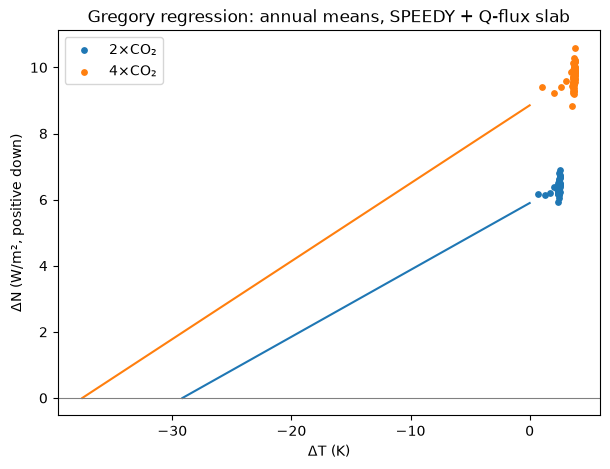

In [14]:
import matplotlib.pyplot as plt

T0 = ab.tas_global_annual_control.values.mean()
N0 = ab.toa_net_global_annual_control.values.mean()

results = {}
fig, ax = plt.subplots(figsize=(7, 5))
for label, run in [("2×CO₂", "2xCO2"), ("4×CO₂", "4xCO2")]:
    dT = ab[f"tas_global_annual_{run}"].values - T0
    dN = ab[f"toa_net_global_annual_{run}"].values - N0

    fit = stats.linregress(dT, dN)          # ΔN = F + λ·ΔT
    results[run] = dict(F=fit.intercept, F_se=fit.intercept_stderr,
                        lam=fit.slope, lam_se=fit.stderr,
                        dT_eq=dT[-10:].mean(), dT_eq_sd=dT[-10:].std())

    print(f"{label}: ERF = {fit.intercept:.2f} ± {fit.intercept_stderr:.2f} W/m² | "
          f"λ = {fit.slope:.2f} ± {fit.stderr:.2f} W/m²/K | "
          f"ΔT(last 10 yr) = {dT[-10:].mean():.2f} K | first-year ΔN = {dN[0]:.2f} W/m²")

    ax.scatter(dT, dN, s=15, label=label)
    x = np.linspace(0, -fit.intercept / fit.slope, 50)
    ax.plot(x, fit.intercept + fit.slope * x)

ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("ΔT (K)")
ax.set_ylabel("ΔN (W/m², positive down)")
ax.set_title("Gregory regression: annual means, SPEEDY + Q-flux slab")
ax.legend()
plt.show()

2×CO₂ (surface flux): intercept = 5.30 ± 0.22 W/m² | λ = 0.18 ± 0.09 W/m²/K | zero crossing ΔT = -28.93 K
4×CO₂ (surface flux): intercept = 7.95 ± 0.29 W/m² | λ = 0.21 ± 0.08 W/m²/K | zero crossing ΔT = -37.75 K


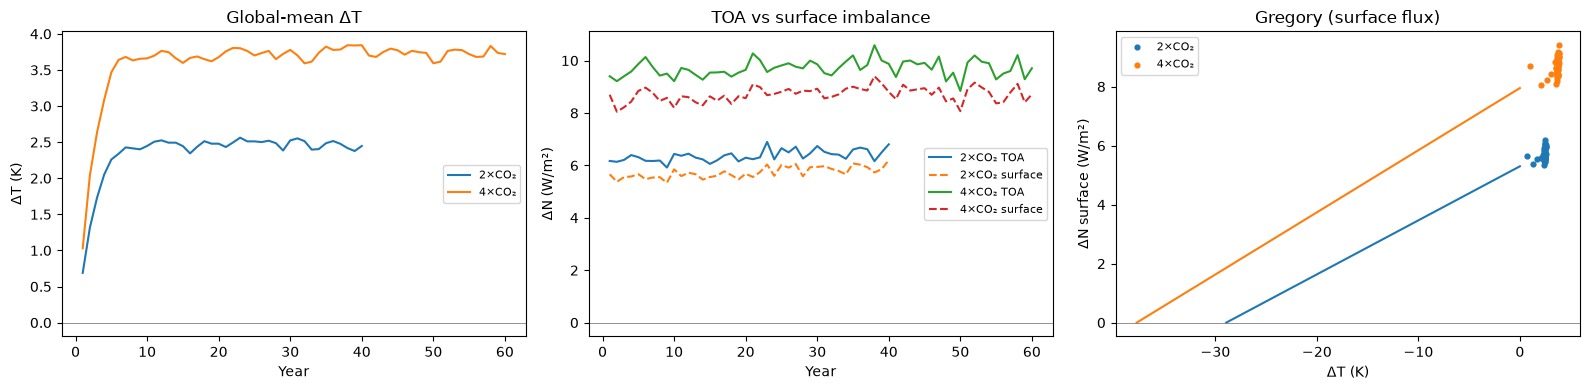

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
S0 = ab.sfc_net_global_annual_control.values.mean()

for run, label in [("2xCO2", "2×CO₂"), ("4xCO2", "4×CO₂")]:
    dT = ab[f"tas_global_annual_{run}"].values - T0
    dN_toa = ab[f"toa_net_global_annual_{run}"].values - N0
    dN_sfc = ab[f"sfc_net_global_annual_{run}"].values - S0
    yrs = np.arange(1, len(dT) + 1)

    axes[0].plot(yrs, dT, label=label)
    axes[1].plot(yrs, dN_toa, label=f"{label} TOA")
    axes[1].plot(yrs, dN_sfc, "--", label=f"{label} surface")

    fit = stats.linregress(dT, dN_sfc)
    print(f"{label} (surface flux): intercept = {fit.intercept:.2f} ± {fit.intercept_stderr:.2f} W/m² | "
          f"λ = {fit.slope:.2f} ± {fit.stderr:.2f} W/m²/K | "
          f"zero crossing ΔT = {-fit.intercept / fit.slope:.2f} K")
    axes[2].scatter(dT, dN_sfc, s=12, label=label)
    x = np.linspace(0, -fit.intercept / fit.slope, 50)
    axes[2].plot(x, fit.intercept + fit.slope * x)

axes[0].set(xlabel="Year", ylabel="ΔT (K)", title="Global-mean ΔT")
axes[1].set(xlabel="Year", ylabel="ΔN (W/m²)", title="TOA vs surface imbalance")
axes[2].set(xlabel="ΔT (K)", ylabel="ΔN surface (W/m²)", title="Gregory (surface flux)")
for a in axes:
    a.axhline(0, color="grey", lw=0.6)
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

2xCO2
  ocean  area 100% | mean ΔN +6.46 W/m² | contributes +6.46 of the global +6.46
  land   area 0% | mean ΔN +nan W/m² | contributes +nan of the global +6.46
4xCO2
  ocean  area 100% | mean ΔN +9.72 W/m² | contributes +9.72 of the global +9.72
  land   area 0% | mean ΔN +nan W/m² | contributes +nan of the global +9.72


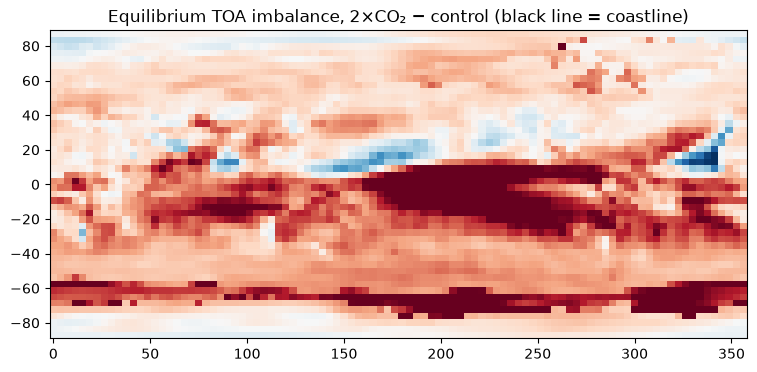

In [21]:
w = np.cos(np.deg2rad(ab.lat))

def ann(v):
    return ab[v].mean("month")

sst_c = ann("sst_eqclim_control")
ocean = sst_c.notnull() & (np.abs(sst_c) < 1e5)
area = w * xr.ones_like(sst_c)

for run in ["2xCO2", "4xCO2"]:
    dN = ann(f"toa_net_eqclim_{run}") - ann("toa_net_eqclim_control")
    print(run)
    total = float((dN * area).sum() / area.sum())
    for name, m in [("ocean", ocean), ("land", ~ocean)]:
        frac = float(area.where(m).sum() / area.sum())
        mean = float((dN * area).where(m).sum() / area.where(m).sum())
        print(f"  {name:<6} area {frac:.0%} | mean ΔN {mean:+.2f} W/m² | "
              f"contributes {mean * frac:+.2f} of the global {total:+.2f}")

dN2 = ann("toa_net_eqclim_2xCO2") - ann("toa_net_eqclim_control")
plt.figure(figsize=(9, 4))
plt.pcolormesh(ab.lon, ab.lat, dN2.transpose("lat", "lon"), cmap="RdBu_r", vmin=-15, vmax=15)
plt.contour(ab.lon, ab.lat, ocean.transpose("lat", "lon").astype(int), levels=[0.5], colors="k", linewidths=0.6)

plt.title("Equilibrium TOA imbalance, 2×CO₂ − control (black line = coastline)")
plt.show()

In [17]:
print("Ocean cells:", int(ocean.sum()), "of", ocean.size)
print("SST on a land cell (Sahara, ~20N 10E):",
      float(sst_c.sel(lat=20, lon=10, method="nearest")))

Ocean cells: 4608 of 4608
SST on a land cell (Sahara, ~20N 10E): 288.1499328613281


In [19]:
sst_m = ab["sst_eqclim_control"]                         # monthly, (month, lon, lat)
land = (np.abs(sst_m - 288.15) < 0.01).all("month")      # 288.15 K in every month
ocean = ~land

print("Ocean cells:", int(ocean.sum()), "of", ocean.size,
      f"({float(ocean.sum()) / ocean.size:.0%})")
print("Sahara is land:", bool(land.sel(lat=20, lon=10, method="nearest")))
print("Mid-Pacific (0N, 180E) is ocean:", bool(ocean.sel(lat=0, lon=180, method="nearest")))

Ocean cells: 3080 of 4608 (67%)
Sahara is land: True
Mid-Pacific (0N, 180E) is ocean: True


In [20]:
area = w * xr.ones_like(ocean, dtype=float)

for run in ["2xCO2", "4xCO2"]:
    dN = ann(f"toa_net_eqclim_{run}") - ann("toa_net_eqclim_control")
    total = float((dN * area).sum() / area.sum())
    print(run)
    for name, m in [("ocean", ocean), ("land", land)]:
        frac = float(area.where(m).sum() / area.sum())
        mean = float((dN * area).where(m).sum() / area.where(m).sum())
        print(f"  {name:<6} area {frac:.0%} | mean ΔN {mean:+.2f} W/m² | "
              f"contributes {mean * frac:+.2f} of the global {total:+.2f}")

2xCO2
  ocean  area 72% | mean ΔN +7.40 W/m² | contributes +5.30 of the global +6.46
  land   area 28% | mean ΔN +4.09 W/m² | contributes +1.16 of the global +6.46
4xCO2
  ocean  area 72% | mean ΔN +10.26 W/m² | contributes +7.35 of the global +9.72
  land   area 28% | mean ΔN +8.37 W/m² | contributes +2.37 of the global +9.72


In [32]:
import pandas as pd
from IPython.display import display

N_YEARS = 8
yearly = {}
summary = []

for run, label in [("2xCO2", "2×CO₂"), ("4xCO2", "4×CO₂")]:
    dT = ab[f"tas_global_annual_{run}"].values - T0
    dN = ab[f"toa_net_global_annual_{run}"].values - N0

    yearly[(label, "ΔT (K)")] = dT[:N_YEARS]
    yearly[(label, "ΔN (W/m²)")] = dN[:N_YEARS]

    fit = stats.linregress(dT[:6], dN[:6])
    summary.append({
        "Run": label,
        "ERF, years 1–6 fit (W/m²)": fit.intercept,
        "λ, years 1–6 fit (W/m²/K)": fit.slope,
        "λ standard error": fit.stderr,
        "Equilibrium ΔT (K)": dT[-10:].mean(),
        "Equilibrium ΔN (W/m²)": dN[-10:].mean(),
        "Equilibrium ΔN/ΔT (W/m²/K)": dN[-10:].mean() / dT[-10:].mean(),
    })

yearly_df = pd.DataFrame(yearly, index=pd.Index(range(1, N_YEARS + 1), name="Year"))
summary_df = pd.DataFrame(summary).set_index("Run")

display(yearly_df.round(2))
display(summary_df.round(2))

2×CO₂            4×CO₂          
     ΔT (K) ΔN (W/m²) ΔT (K) ΔN (W/m²)
Year                                  
1      0.69      6.17   1.03      9.40
2      1.32      6.14   2.04      9.21
3      1.73      6.21   2.64      9.40
4      2.05      6.39   3.09      9.58
5      2.26      6.32   3.47      9.87
6      2.34      6.18   3.64     10.14
7      2.43      6.17   3.68      9.76
8      2.41      6.19   3.63      9.43

,"ERF, years 1–6 fit (W/m²)","λ, years 1–6 fit (W/m²/K)",λ standard error,Equilibrium ΔT (K),Equilibrium ΔN (W/m²),Equilibrium ΔN/ΔT (W/m²/K)
Run,,,,,,
2×CO₂,6.09,0.08,0.07,2.46,6.50,2.64
4×CO₂,8.89,0.27,0.11,3.73,9.76,2.62


In [29]:
### Reporting the ECS, as the equilibrium

In [31]:
import pandas as pd

noresm2_ecs = 2.5                 # Seland et al. (2020), approximate; verify exact value
ar6_best = 3.0
ar6_likely = (2.5, 4.0)
ar6_very_likely = (2.0, 5.0)

def where(x, lo, hi):
    return "inside" if lo <= x <= hi else ("below" if x < lo else "above")

rows = [
    ("SPEEDY: equilibrium ΔT (2×CO₂)",   ecs_eq,      "last 10 yr of 2×CO₂ run"),
    ("SPEEDY: 4×CO₂ scaled by F₂ₓ/F₄ₓ",  ecs_from_4x, "cross-check"),
    ("SPEEDY: −F₂ₓ/λ (Gregory)",         ecs_reg,     "unphysical: λ > 0"),
    ("NorESM2-LM",                        noresm2_ecs, "Seland et al. (2020)"),
    ("IPCC AR6 best estimate",            ar6_best,    "Forster et al. (2021)"),
]

df = pd.DataFrame(rows, columns=["Estimate", "ECS (K)", "Note"])
df["Δ vs NorESM2 (K)"] = df["ECS (K)"] - noresm2_ecs
df["Δ vs AR6 best (K)"] = df["ECS (K)"] - ar6_best
df["AR6 likely (2.5–4 K)"] = df["ECS (K)"].apply(lambda x: where(x, *ar6_likely))
df["AR6 very likely (2–5 K)"] = df["ECS (K)"].apply(lambda x: where(x, *ar6_very_likely))
df = df.set_index("Estimate")

df.round(2)

,ECS (K),Note,Δ vs NorESM2 (K),Δ vs AR6 best (K),AR6 likely (2.5–4 K),AR6 very likely (2–5 K)
Estimate,,,,,,
SPEEDY: equilibrium ΔT (2×CO₂),2.46,last 10 yr of 2×CO₂ run,-0.04,-0.54,below,inside
SPEEDY: 4×CO₂ scaled by F₂ₓ/F₄ₓ,2.49,cross-check,-0.01,-0.51,below,inside
SPEEDY: −F₂ₓ/λ (Gregory),-29.15,unphysical: λ > 0,-31.65,-32.15,below,below
NorESM2-LM,2.50,Seland et al. (2020),0.00,-0.50,inside,inside
IPCC AR6 best estimate,3.00,Forster et al. (2021),0.50,0.00,inside,inside


In [37]:
DATA = "/home/vpaidi/private/Dsc-180/"
TRAIN_SCENARIOS = ["historical", "ssp585", "ssp126", "ssp370"]
MEMBER = {"historical": 2, "ssp126": 1, "ssp370": 1, "ssp585": 1}   # same choices as week 3

def load_targets(s):
    ds = xr.open_dataset(DATA + f"outputs_{s}.nc").sel(member=MEMBER[s])
    ds["pr"] = ds["pr"] * 86400                                     # kg m⁻² s⁻¹ → mm/day
    return ds[["tas", "pr"]].load()

def global_mean(field):
    return field.weighted(np.cos(np.deg2rad(field.lat))).mean(["lat", "lon"])

Y = xr.concat([load_targets(s) for s in TRAIN_SCENARIOS], dim="time")
gmt = global_mean(Y["tas"]).values.reshape(-1, 1)
n = len(gmt)

nor = {}
for var in ["tas", "pr"]:
    y = Y[var].values.reshape(n, -1)
    alpha = np.linalg.lstsq(gmt, y, rcond=None)[0]                  # same fit as week 3
    nor[var] = xr.DataArray(alpha.reshape(Y.sizes["lat"], Y.sizes["lon"]),
                            coords={"lat": Y.lat, "lon": Y.lon}, dims=["lat", "lon"])
    
wn = np.cos(np.deg2rad(nor["tas"].lat))
print("Training timesteps:", n)
print("NorESM2 tas pattern, global mean (should be ~1):",
      round(float(nor["tas"].weighted(wn).mean()), 3))

/tmp/ipykernel_297/857682473.py:13: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords explicitly.
  Y = xr.concat([load_targets(s) for s in TRAIN_SCENARIOS], dim="time")


Training timesteps: 423
NorESM2 tas pattern, global mean (should be ~1): 1.0


In [39]:
area = w * xr.ones_like(land, dtype=float)                    # SPEEDY cell weights

def gmean(x):
    return float((x * area).sum() / area.sum())

pat = {}
for run in ["2xCO2", "4xCO2"]:
    dT = (ann(f"tas_eqclim_{run}") - ann("tas_eqclim_control")).transpose("lat", "lon")
    dP = (ann(f"pr_eqclim_{run}") - ann("pr_eqclim_control")).transpose("lat", "lon")
    g = gmean(dT)
    pat[run] = {"tas": dT / g, "pr": dP / g}
    P0 = gmean(ann("pr_eqclim_control"))
    print(f"SPEEDY {run}: global ΔT {g:.2f} K | global ΔP {gmean(dP):+.3f} mm/day "
          f"= {100 * gmean(dP) / P0 / g:.1f} %/K")

nor_s = {v: nor[v].interp(lat=pat["2xCO2"]["tas"].lat, lon=pat["2xCO2"]["tas"].lon)
         for v in ["tas", "pr"]}

SPEEDY 2xCO2: global ΔT 2.46 K | global ΔP +0.189 mm/day = 2.7 %/K
SPEEDY 4xCO2: global ΔT 3.73 K | global ΔP +0.255 mm/day = 2.4 %/K


In [40]:
land2 = land.transpose("lat", "lon")
ocean2 = ~land2

def wmean(x, m):
    return float((x * area.transpose("lat", "lon")).where(m).sum() /
                 area.transpose("lat", "lon").where(m).sum())

def pattern_corr(a, b):
    wa = area.transpose("lat", "lon")
    am, bm = gmean(a), gmean(b)
    cov = float(((a - am) * (b - bm) * wa).sum())
    return cov / np.sqrt(float(((a - am) ** 2 * wa).sum()) * float(((b - bm) ** 2 * wa).sum()))

rows = []
for var, unit in [("tas", "K/K"), ("pr", "mm/day/K")]:
    s, n2 = pat["2xCO2"][var], nor_s[var]
    rows.append({
        "Variable": f"{var} ({unit})",
        "Pattern corr.": pattern_corr(s, n2),
        "RMS diff": np.sqrt(gmean((s - n2) ** 2)),
        "SPEEDY land": wmean(s, land2), "NorESM2 land": wmean(n2, land2),
        "SPEEDY ocean": wmean(s, ocean2), "NorESM2 ocean": wmean(n2, ocean2),
        "SPEEDY Arctic (>60N)": wmean(s, s.lat > 60), "NorESM2 Arctic (>60N)": wmean(n2, n2.lat > 60),
        "SPEEDY 4× vs 2× corr.": pattern_corr(pat["4xCO2"][var], s),
    })
display(pd.DataFrame(rows).set_index("Variable").round(2))

,Pattern corr.,RMS diff,SPEEDY land,NorESM2 land,SPEEDY ocean,NorESM2 ocean,SPEEDY Arctic (>60N),NorESM2 Arctic (>60N),SPEEDY 4× vs 2× corr.
Variable,,,,,,,,,
tas (K/K),-0.34,0.84,0.89,1.45,1.04,0.82,0.44,2.16,0.97
pr (mm/day/K),-0.04,0.73,-0.07,0.02,0.13,0.03,0.06,0.08,0.94


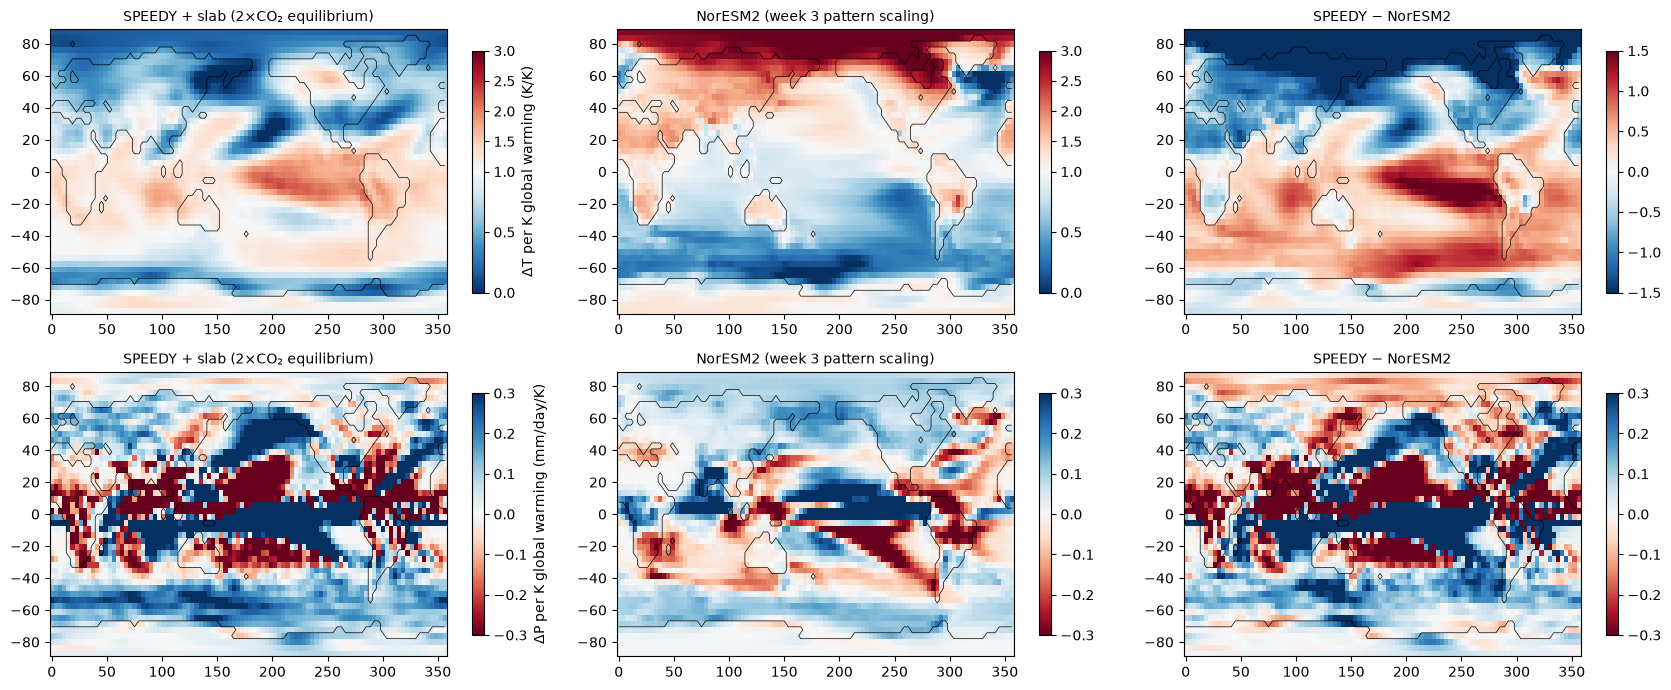

In [44]:
from matplotlib import colors


fig, axes = plt.subplots(2, 3, figsize=(17, 7))
specs = [("tas", "RdBu_r", (0, 3), 1.5, "ΔT per K global warming (K/K)"),
         ("pr", "RdBu", (-0.3, 0.3), 0.3, "ΔP per K global warming (mm/day/K)")]

for row, (var, cmap, lim, dlim, lab) in enumerate(specs):
    s, n2 = pat["2xCO2"][var], nor_s[var]
    panels = [(s, "SPEEDY + slab (2×CO₂ equilibrium)", lim, cmap),
              (n2, "NorESM2 (week 3 pattern scaling)", lim, cmap),
              (s - n2, "SPEEDY − NorESM2", (-dlim, dlim), "RdBu_r" if var == "tas" else "RdBu")]
    for col, (field, title, (lo, hi), cm) in enumerate(panels):
        ax = axes[row, col]
        if var == "tas" and col < 2:
            norm = colors.TwoSlopeNorm(vmin=lo, vcenter=1, vmax=hi)
            mesh = ax.pcolormesh(field.lon, field.lat, field, cmap=cm, norm=norm)
        else:
            mesh = ax.pcolormesh(field.lon, field.lat, field, cmap=cm, vmin=lo, vmax=hi)
        ax.contour(land2.lon, land2.lat, land2.astype(int), levels=[0.5], colors="k", linewidths=0.5)
        ax.set_title(title, fontsize=10)
        fig.colorbar(mesh, ax=ax, label=lab if col == 0 else "", shrink=0.85)
plt.tight_layout()
plt.show()